# 04 · Robustness, polynomial shape and honest validation

**Synthetic illustration — Not empirical research results**

Robustness asks how an estimand changes across defensible specifications; it
is not a search for a preferred significant coefficient. This notebook uses
a seeded, curved artificial series to inspect bandwidths and P1/P2/P3, then
distinguishes file identity, sample identity and numerical agreement.

**Learn to:** validate P1 before higher orders; keep all post interactions;
inspect shape/support warnings; and preserve blocked statuses. This is a small
teaching subset, not the formal V3/V3.2 model inventory.
See [research hierarchy and limitations](../docs/methodology.md).


In [1]:
import numpy as np
import pandas as pd
# Keep table outputs plain text for the public safety profile.
pd.set_option("display.notebook_repr_html", False)
import matplotlib.pyplot as plt
from IPython.display import display

LABEL = "Synthetic illustration — Not empirical research results"
plt.rcParams.update({"figure.facecolor": "white", "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titlesize": 12,
                     "axes.labelsize": 10, "font.size": 10})
DEMO_LABEL = "SYNTHETIC DATA — NOT EMPIRICAL RESEARCH RESULTS"
print(DEMO_LABEL)
print(LABEL)


SYNTHETIC DATA — NOT EMPIRICAL RESEARCH RESULTS
Synthetic illustration — Not empirical research results


## 1. A deliberately curved artificial local series

The fixture's invented discontinuity is augmented with smooth curvature and
seeded disturbances. For a teaching bandwidth $h=10$, the polynomial running
variable is $z=r/h$. P1, P2 and P3 all include
$z^k$ **and** $Post\times z^k$ for each included order $k$.


In [2]:
from cbam_power._demo import artificial_native
from cbam_power.market import integrate_native
from cbam_power.design import calendar, local
from cbam_power.estimators import fit
from cbam_power import polynomial

t, values = artificial_native()
frame = integrate_native(t, values, 15, "scheduled_export_proxy").reset_index()
frame = calendar(frame.assign(corridor_id="ME_IT", delivery_interval_minutes=60))
q = polynomial.sample(frame, "ME", 10, 2026)
rng = np.random.default_rng(73023)
q["scheduled_export_proxy"] += 7*q.z**2 - 4*q.post*q.z**2 + 2*q.z**3 + rng.normal(0, 1.5, len(q))
# Copy the artificial outcome into the original schema for all bandwidths.
frame["scheduled_export_proxy"] = q.scheduled_export_proxy.to_numpy()
assert q.timestamp_utc.is_unique and len(q) == 480


## 2. P1 first; then P2 and P3 on the same sample

The first check compares the existing linear RDiT design with its scaled P1
representation. Higher orders then call the same package estimator and its
existing shape diagnostic. The notebook assembles only presentation metadata;
it contains no second implementation of WLS, HAC or polynomial diagnostics.
Every teaching model has a `DEMO_` ID.


In [3]:
linear = fit(local(frame, 10), "scheduled_export_proxy", ["post", "r", "post_r"],
             fe=("hour", "weekday"), weight="triangular")
models, diagnostics, plotted_curves = [], [], []
polynomial_sample_digests = []
transformation_symmetry_errors = []
first_order = None
for order in [1, 2, 3]:
    sample = polynomial.sample(frame, "ME", 10, 2026)
    sample, names = polynomial.terms(sample, order)
    result = fit(sample, "scheduled_export_proxy", names,
                 fe=("hour", "weekday"), weight="triangular")
    covariance = result.covariance(168)
    contrast = result.contrast(covariance, {"post": 1})
    model = {"model_id": f"DEMO_P{order}", "polynomial_order": order,
             "bandwidth_days": 10, "columns": result.names,
             "beta": result.beta.tolist(), "covariance": covariance.tolist(),
             "tau": contrast["coefficient"], "se": contrast["se"],
             "condition_number": result.audit["condition_number"]}
    if order == 1:
        p1_tau_error = float(abs(model["tau"]-linear.beta[linear.names.index("post")]))
        p1_fitted_error = float(np.max(np.abs(result.x @ result.beta-linear.x @ linear.beta)))
        assert np.isclose(model["tau"], linear.beta[linear.names.index("post")], atol=1e-9, rtol=0)
        assert np.allclose(result.x @ result.beta, linear.x @ linear.beta, atol=1e-9, rtol=0)
        first_order = model
    else:
        assert first_order is not None  # P1 must have passed first.
    shape, lines, bins = polynomial.shape_qa(model, result, first_order)
    transformed_names, transformed_beta, transformed_cov = polynomial.transform_to_elapsed_days(model)
    transformation_symmetry_errors.append(float(np.max(np.abs(transformed_cov-transformed_cov.T))))
    assert np.allclose(transformed_cov, transformed_cov.T, atol=1e-12, rtol=0)
    polynomial_sample_digests.append(result.sample_hash)
    assert np.isclose(transformed_beta[transformed_names.index("post")], model["tau"])
    models.append(model)
    diagnostics.append({"model_id": model["model_id"], "order": order,
        "jump_MW": model["tau"], "HAC168_SE": model["se"], "N": len(result.y),
        "condition_number": model["condition_number"],
        "turning_points": len(shape["turning_points"]), "flags": "; ".join(shape["flags"]) or "none"})
    plotted_curves.append(pd.DataFrame(lines))
display(pd.DataFrame(diagnostics))

assert len(set(polynomial_sample_digests)) == 1  # All three orders use identical UTC observations.


  model_id  order   jump_MW  HAC168_SE    N  condition_number  turning_points  \
0  DEMO_P1      1  4.122300   0.403313  480         30.207964               0   
1  DEMO_P2      2  5.245022   0.287288  480         83.455655               0   
2  DEMO_P3      3  5.195065   0.283409  480        471.756768               2   

                                  flags  
0                                  none  
1                                  none  
2  CUBIC_TWO_TURNING_POINTS_ON_ONE_SIDE  

## 3. Inspect curves as well as cutoff coefficients

Shape warnings describe low-weight endpoints, weak local support around a
turning point, negative predictions or instability. They are not an automatic
deletion rule. The curves below are package-generated predictions at omitted
calendar categories, not unconditional hourly forecasts.


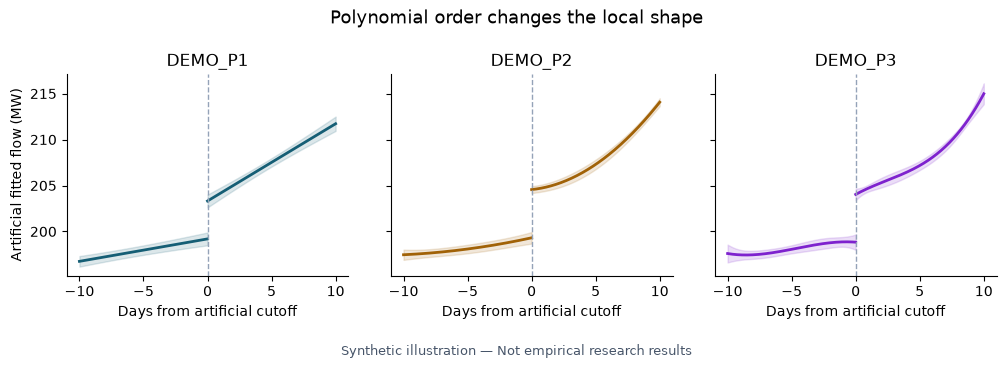

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True)
for axis, model, curves, color in zip(axes, models, plotted_curves,
                                     ["#155e75", "#a16207", "#7e22ce"]):
    for _, side in curves.groupby("post"):
        axis.plot(side.r_days, side.fitted, color=color, linewidth=2)
        axis.fill_between(side.r_days, side.ci_low, side.ci_high, color=color, alpha=.15)
    axis.axvline(0, color="#94a3b8", linestyle="--", linewidth=1)
    axis.set(title=model["model_id"], xlabel="Days from artificial cutoff")
axes[0].set_ylabel("Artificial fitted flow (MW)")
fig.suptitle("Polynomial order changes the local shape", fontsize=13)
fig.text(.5, .02, LABEL, ha="center", fontsize=9, color="#475569")
fig.subplots_adjust(bottom=.24, top=.8, wspace=.15)
plt.show()


## 4. Bandwidth sensitivity and a transparent negative-control example

The reduced bandwidth grid below is instructional. We retain every result,
including a blocked fit when calendar effects make a very short window
rank-deficient; the notebook does not remove controls to force an estimate.
No specification is selected by its sign or significance. The placebo
series removes the artificial jump/slope change and moves the same calendar
experiment back one year. Its noise is left intact. A single noisy placebo
estimate is not an identification certificate.


In [5]:
from cbam_power.estimators import NotEstimable

sensitivity = []
for bandwidth in [4, 7, 8, 10]:
    selected = local(frame, bandwidth)
    try:
        local_fit = fit(selected, "scheduled_export_proxy", ["post", "r", "post_r"],
                        fe=("hour", "weekday"), weight="triangular")
    except NotEstimable as error:
        sensitivity.append({"model_id": f"DEMO_BW{bandwidth}",
            "bandwidth_days": bandwidth, "N": len(selected), "status": str(error)})
        continue
    effect = local_fit.contrast(local_fit.covariance(168), {"post": 1})
    sensitivity.append({"model_id": f"DEMO_BW{bandwidth}", "bandwidth_days": bandwidth,
                        "N": len(local_fit.y), "status": "ESTIMATED", **effect})
display(pd.DataFrame(sensitivity)[["model_id", "N", "status", "coefficient", "ci_low", "ci_high"]])

placebo_t, placebo_y = artificial_native()
placebo_frame = integrate_native(placebo_t, placebo_y, 15, "scheduled_export_proxy").reset_index()
original = local(calendar(placebo_frame), 10)
placebo_frame["scheduled_export_proxy"] -= 4*original.post - .2*original.post*original.r
placebo_frame["scheduled_export_proxy"] += np.random.default_rng(73024).normal(0, 1.5, len(placebo_frame))
placebo_frame["timestamp_utc"] -= pd.DateOffset(years=1)
placebo_sample = local(calendar(placebo_frame), 10, cutoff=2025)
placebo_fit = fit(placebo_sample, "scheduled_export_proxy", ["post", "r", "post_r"],
                  fe=("hour", "weekday"), weight="triangular")
placebo_effect = placebo_fit.contrast(placebo_fit.covariance(168), {"post": 1})
display(pd.DataFrame([{"model_id": "DEMO_PLACEBO_2025", **placebo_effect}]))


    model_id    N        status  coefficient    ci_low   ci_high
0   DEMO_BW4  192  BLOCKED_RANK          NaN       NaN       NaN
1   DEMO_BW7  336  BLOCKED_RANK          NaN       NaN       NaN
2   DEMO_BW8  384     ESTIMATED     4.348605  3.897639  4.799570
3  DEMO_BW10  480     ESTIMATED     4.122300  3.331807  4.912794

            model_id  coefficient        se    ci_low  ci_high   p_value
0  DEMO_PLACEBO_2025    -0.019224  0.086569 -0.188899  0.15045  0.824262

## 5. File hashes and sample hashes answer different questions

Two byte encodings can represent identical information. Equality must be
demonstrated from the underlying values; it cannot be assumed from different
hash formats. Here we verify timestamps explicitly before bridging microsecond
and nanosecond representations. Formal comparisons also require identical
model IDs, coefficient order, missing masks, covariance references and statuses.


In [6]:
import hashlib
import json
from cbam_power.validation import timestamp_proof

timestamps = pd.DatetimeIndex(frame.timestamp_utc)
ns = timestamps.as_unit("ns").asi8.astype("<i8")
us = timestamps.as_unit("us").asi8.astype("<i8")
hash_ns = hashlib.sha256(ns.tobytes()).hexdigest()
hash_us = hashlib.sha256(us.tobytes()).hexdigest()
assert hash_ns != hash_us
assert np.array_equal(ns, us*1000)  # Actual timestamps, not a digest exemption.
assert timestamp_proof(ns, ns.copy(), hash_us) == "us"

tiny = {"model_id": "DEMO_ONLY", "value": 1.25}
compact, pretty = json.dumps(tiny).encode(), json.dumps(tiny, indent=2).encode()
assert hashlib.sha256(compact).hexdigest() != hashlib.sha256(pretty).hexdigest()
assert json.loads(compact) == json.loads(pretty)
print("Byte hashes differ; sample/value equality was checked directly.")
known_checks = pd.DataFrame(polynomial.known_polynomials())
display(known_checks)
assert known_checks.status.eq("PASS").all()


Byte hashes differ; sample/value equality was checked directly.


                             check status         error
0                   known_P1_BASIC   PASS -1.847411e-13
1                      known_P1_FE   PASS -2.842171e-13
2                   known_P2_BASIC   PASS -1.705303e-13
3                      known_P2_FE   PASS -6.110668e-13
4                   known_P3_BASIC   PASS -1.278977e-13
5                      known_P3_FE   PASS -1.051603e-12
6  elapsed_HAC_with_missing_blocks   PASS  2.728484e-12

The P1 coefficient and fitted values agree with the linear design before P2/P3
are run. The three polynomial fits retain identical UTC keys; their curve
shapes can differ because their designs differ. The separate known-polynomial
checks exercise deterministic equations with known coefficients and an
independent elapsed-hour HAC calculation already supplied by the package.
Passing those checks does not waive the full private frozen-result comparison.


## 6. Statuses and research hierarchy are part of the result

The package's registered 2024 polynomial placebo status below records missing
pre-cutoff support. It is a design limitation, not a model estimated by this
notebook. Annual weather limitations, blocked CH synthetic and FR's formal
exclusion are likewise not repaired by dropping checks or manufacturing data.

Formal V3 is the baseline; V3.1 is presentation; V3.2 adds polynomial robustness.
F1 compares same-season levels and F2 compares spread-response slopes; neither
is the local cutoff jump shown here. A public teaching run establishes only
artificial-data execution. Frozen scientific validation, provider permissions
and publication approval remain separate gates.


In [7]:
registered_status = pd.DataFrame(polynomial.not_estimated_models())
display(registered_status[["status", "detail"]].drop_duplicates().reset_index(drop=True))
print("No registered missing-support model was estimated or silently enabled.")


                     status                                          detail
0  INSUFFICIENT_PRE_SUPPORT  No 2023 pre-cutoff observations; not estimated

No registered missing-support model was estimated or silently enabled.


Return to [data and weather](01_data_and_weather.ipynb),
[RDiT/HAC](02_rdit_and_hac.ipynb), [synthetic comparisons](03_synthetic_control.ipynb)
or the [full methodology](../docs/methodology.md).


## Reproducible numerical checkpoints

The following values summarize this artificial run. The teaching runner
compares them across clean-kernel executions; they are not empirical
baselines. All values come from the calculations above, with no private
inputs or fitted research values. Presentation rounding does not change
the unrounded checkpoints.


In [8]:
PUBLIC_NUMERICAL_CHECKPOINTS = {
    "example": "DEMO_ROBUSTNESS_VALIDATION", "seed": 73023, "placebo_seed": 73024,
    "sample_hours": int(len(frame)),
    "polynomial_orders": [int(m["polynomial_order"]) for m in models],
    "polynomial_jumps_MW": [float(m["tau"]) for m in models],
    "polynomial_HAC168_se": [float(m["se"]) for m in models],
    "polynomial_condition_numbers": [float(m["condition_number"]) for m in models],
    "polynomial_turning_point_counts": [int(d["turning_points"]) for d in diagnostics],
    "polynomial_shape_flags": [str(d["flags"]) for d in diagnostics],
    "p1_tau_absolute_error": float(p1_tau_error),
    "p1_fitted_max_absolute_error": float(p1_fitted_error),
    "transformed_covariance_symmetry_max_error": float(max(transformation_symmetry_errors)),
    "same_sample_across_orders": bool(len(set(polynomial_sample_digests)) == 1),
    "artificial_sample_ns_sha256": hash_ns,
    "microsecond_bridge_confirmed": bool(timestamp_proof(ns, ns.copy(), hash_us) == "us"),
    "bandwidth_statuses": {str(row["bandwidth_days"]): row["status"] for row in sensitivity},
    "estimated_bandwidth_jumps_MW": {str(row["bandwidth_days"]): float(row["coefficient"])
                                      for row in sensitivity if row["status"] == "ESTIMATED"},
    "placebo_jump_MW": float(placebo_effect["coefficient"]),
    "placebo_HAC168_se": float(placebo_effect["se"]),
    "known_math_checks_passed": int(known_checks.status.eq("PASS").sum()),
    "known_math_max_error": float(known_checks.error.abs().max()),
    "unavailable_design_status_count": int(len(registered_status))}


import json
json.dumps(PUBLIC_NUMERICAL_CHECKPOINTS, allow_nan=False, sort_keys=True)
display(pd.DataFrame({"checkpoint": list(PUBLIC_NUMERICAL_CHECKPOINTS),
                      "value": list(PUBLIC_NUMERICAL_CHECKPOINTS.values())}))


                                   checkpoint  \
0                                     example   
1                                        seed   
2                                placebo_seed   
3                                sample_hours   
4                           polynomial_orders   
5                         polynomial_jumps_MW   
6                        polynomial_HAC168_se   
7                polynomial_condition_numbers   
8             polynomial_turning_point_counts   
9                      polynomial_shape_flags   
10                      p1_tau_absolute_error   
11               p1_fitted_max_absolute_error   
12  transformed_covariance_symmetry_max_error   
13                  same_sample_across_orders   
14                artificial_sample_ns_sha256   
15               microsecond_bridge_confirmed   
16                         bandwidth_statuses   
17               estimated_bandwidth_jumps_MW   
18                            placebo_jump_MW   
19                  